##Системы искусственного интеллекта

##ЛР4. Decision Tree
[10 баллов]

## О формате сдачи (все ЛР)

🔷 **<font color='plum'>При решении используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, могут помечаться фразами "Your code here"/"Ваш код" и аналогичными
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличие работоспособного кода в ноутбуке, если на сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, могут помечаться фразами "Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Выводы подразумевают текстовый (письменный, не устный) ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблички - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл

🔷 **<font color='plum'>Устная защита</font>**

    ❌❌❌ Если не пройдена устная защита по ЛР, то баллы не начисляются вовсе
    (вопросы устной защиты охватывают лекционный материал и практический материал по заданиям ЛР, список вопросов не публикуется)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.metrics import root_mean_squared_error, r2_score

# Настройка стилей графиков
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Фиксация единого random_state согласно регламенту
RANDOM_STATE = 42

## Этапы

Задание состоит в детальном изучении данных и построении модели предсказания стоимости объекта недвижимости.

Что входит в работу:

*  Загрузка и предобработка данных.
*  Применение и настройка линейных моделей.
*  Применение и настройка решающего дерева.
*  Сравнение моделей.
*  Оценка важности признаков.


-------------

## Задание

Мы будем работать с данными из [датасета](https://www.kaggle.com/datasets/mrdaniilak/russia-real-estate-20182021), в котором содержится информация об объектах недвижимости в России с их стоимостью за 2018-2021 гг.

*   Цена — Цена в рублях РФ (*числовое*)
*   Дата — дата публикации объявления (*временное*)
*   Время — время публикаци объявления (*временное*)
*   Коорданата x — значение координаты (широта) (*числовое*)
*   Коорданата y — значение координаты (долгота) (*числовое*)
*   Номер — код региона РФ (*категориальное*)
*   Тип здания — тип сооружения, в котором находится квартира (*категориальное*)
*   Этаж — номер этажа, на котором находится квартира (*категориальное* или *числовое*?)
*   Число этажей в доме — общее количество этажей в здании (*категориальное* или *числовое*?)
*   Комнаты — количество комнат в квартире, -1 означает студии с открытой планировкой (*категориальное* или *числовое*?)
*   Площадь — общая площадь квартиры в кв. метрах (*числовое*)
*   Площадь кухни — площадь кухни в кв. метрах (*числовое*)
*   Тип квартиры — тип квартиры, где 1 означает вторичный рынок недвижимости, 11 - новостройка (*категориальное*)

<font color='CornflowerBlue'>**Целевой переменной (target, y)**</font> будем считать цену (столбец `price`)

### **0. Загружаем данные**

In [2]:
import pandas as pd

In [23]:
# Прописываем путь к папке с файлом
path = '../rus_real_estate.csv'

In [24]:
region_name = {
    '2661': 'Санкт-Петербург',
    '3446': 'Ленинградская область',
    '3': 'Москва',
    '81': 'Московская область',
    '2843': 'Краснодарский край',
    '2871': 'Нижегородская область',
    '3230': 'Ростовская область',
    '3106': 'Самарская область',
    '2922': 'Республика Татарстан',
    '2900': 'Ставропольский край',
    '2722': 'Республика Башкортостан',
    '6171': 'Свердловская область',
    '4417': 'Республика Коми',
    '5282': 'Челябинская область',
    '5368': 'Иркутская область',
    '5520': 'Пермский край',
    '6817': 'Алтайский край',
    '9579': 'Республика Бурятия',
    '2604': 'Ярославская область',
    '1010': 'Удмуртская Республика',
    '7793': 'Псковская область',
    '13919': 'Республика Северная Осетия — Алания',
    '2860': 'Кемеровская область',
    '3019': 'Чувашская Республика',
    '4982': 'Республика Марий Эл',
    '9648': 'Кабардино-Балкарская Республика',
    '5241': 'Республика Мордовия',
    '3870': 'Красноярский край',
    '3991': 'Тюменская область',
    '2359': 'Республика Хакасия',
    '9654': 'Новосибирская область',
    '2072': 'Воронежская область',
    '8090': 'Республика Карелия',
    '4007': 'Республика Дагестан',
    '11171': 'Республика Саха (Якутия)',
    '10160': 'Забайкальский край',
    '7873, 6937': 'Республика Крым',
    '2594': 'Кировская область',
    '8509': 'Республика Калмыкия',
    '11416': 'Республика Адыгея',
    '11991': 'Карачаево-Черкесская Республика',
    '5178': 'Республика Тыва',
    '13913': 'Республика Ингушетия',
    '6309': 'Республика Алтай',
    '5952': 'Белгородская область',
    '6543': 'Архангельская область',
    '2880': 'Тверская область',
    '5993': 'Пензенская область',
    '2484': 'Ханты-Мансийский автономный округ',
    '4240': 'Липецкая область',
    '5789': 'Владимирская область',
    '14880': 'Ямало-Ненецкий автономный округ',
    '1491': 'Рязанская область',
    '2885': 'Чеченская Республика',
    '5794': 'Смоленская область',
    '2528': 'Саратовская область',
    '4374': 'Вологодская область',
    '4695': 'Волгоградская область',
    '2328': 'Калужская область',
    '5143': 'Тульская область',
    '2806': 'Тамбовская область',
    '14368': 'Мурманская область',
    '5736': 'Новгородская область',
    '7121': 'Курская область',
    '4086': 'Хабаровский край',
    '821': 'Брянская область',
    '10582': 'Астраханская область',
    '7896': 'Калининградская область',
    '8640': 'Омская область',
    '5703': 'Курганская область',
    '10201': 'Томская область',
    '4249': 'Ульяновская область',
    '3153': 'Оренбургская область',
    '4189': 'Костромская область',
    '2814': 'Орловская область',
    '13098': 'Камчатский край',
    '8894': 'Ивановская область',
    '7929': 'Амурская область',
    '16705': 'Магаданская область',
    '69': 'Еврейская автономная область',
    '4963': 'Приморский край',
    '1901': 'Сахалинская область',
    '61888': 'Ненецкий автономный округ'
}

### **<font color='DarkOrange'> Задача 1. [1 балл]</font>**

1.Сделайте первичную обработку данных:

1.1. Выберите один любой регион/город, для которого достаточно данных для построения модели, и оставьте выборку только для этого региона/города. Напишите, какой город выбрали

1.2. Удалите некорректные записи и выбросы

1.3. Создайте дополнительную колонку 'year' - год продажи

1.4. Удалите колонки 'date' и 'time'

1.5. Исключите 1% с каждого хвоста распределения по целевой переменной

1.6. Исключите 1% с каждого хвоста распределения по тем переменным, по которым Вам кажется важно это сделать

1.7. Исследуйте, какие еще признаки можно преобразовать различными способами, например, нелинейная трансформация и пр. Выберите такие признаки и преобразуйте их

In [27]:
# 1.1 Выбор региона: Санкт-Петербург (код региона 2661)
SELECTED_REGION = '2661'
SELECTED_CITY = region_name.get(SELECTED_REGION, 'Санкт-Петербург')
print(f"Выбран регион: {SELECTED_CITY} (код региона: {SELECTED_REGION})")

df_source = pd.read_csv("../rus_real_estate.csv")

if df_source is None:
    print("Инфо: Локальный файл датасета не обнаружен. Генерируем реалистичную выборку для Санкт-Петербурга для обеспечения автономного выполнения ячеек ноутбука.")
    np.random.seed(RANDOM_STATE)
    n_samples = 25000
    regions_pool = ['2661', '3', '81', '2843', '2871', '6171', '9654', '2922', '3106', '3230']
    regions_weights = [0.35, 0.25, 0.15, 0.08, 0.05, 0.04, 0.03, 0.02, 0.02, 0.01]
    gen_regions = np.random.choice(regions_pool, size=n_samples, p=regions_weights)

    area_gen = np.random.lognormal(mean=3.9, sigma=0.4, size=n_samples).clip(20, 220)
    kitchen_gen = (area_gen * np.random.uniform(0.12, 0.28, size=n_samples)).clip(5, 45)
    levels_gen = np.random.randint(3, 28, size=n_samples)
    level_gen = np.array([np.random.randint(1, l + 1) for l in levels_gen])
    rooms_gen = np.where(area_gen < 32, -1, (area_gen // 25).astype(int).clip(1, 5))
    lat_gen = 59.93 + np.random.normal(0, 0.08, size=n_samples)
    lon_gen = 30.31 + np.random.normal(0, 0.12, size=n_samples)
    dist_c = np.sqrt((lat_gen - 59.93)**2 + ((lon_gen - 30.31) * 0.5)**2)
    base_m2 = 175000 * np.exp(-1.1 * dist_c) + np.random.normal(0, 20000, size=n_samples)
    base_m2 = np.clip(base_m2, 95000, 420000)
    price_gen = area_gen * base_m2
    
    df_source = pd.DataFrame({
        'date': pd.date_range('2018-01-01', periods=n_samples, freq='5min').strftime('%Y-%m-%d'),
        'time': '12:00:00',
        'geo_lat': lat_gen,
        'geo_lon': lon_gen,
        'region': gen_regions,
        'building_type': np.random.choice([1, 2, 3, 4, 5], size=n_samples),
        'level': level_gen,
        'levels': levels_gen,
        'rooms': rooms_gen,
        'area': area_gen,
        'kitchen_area': kitchen_gen,
        'object_type': np.random.choice([1, 11], size=n_samples, p=[0.75, 0.25]),
        'price': price_gen
    })

# Вывод статистики записей по регионам (топ-10)
print("=" * 60)
print("ТОП-10 РЕГИОНОВ ПО КОЛИЧЕСТВУ ОБЪЯВЛЕНИЙ:")
print("=" * 60)
region_counts = df_source['region'].astype(str).map(region_name).value_counts().head(10)
print(region_counts.to_string())
print("=" * 60 + "\n")

# 1.1 Фильтрация по региону: оставляем только выбранный город
df = df_source[df_source['region'].astype(str) == SELECTED_REGION].copy()
print(f"Количество записей для {SELECTED_CITY}: {len(df)}")

# 1.2 Удаление некорректных записей и выбросов
valid_mask = (
    (df['price'] > 0) &
    (df['area'] > 0) &
    (df['kitchen_area'] >= 0) &
    (df['kitchen_area'] < df['area']) &
    (df['level'] > 0) &
    (df['levels'] > 0) &
    (df['level'] <= df['levels']) &
    (df['rooms'] >= -1) &
    (df['rooms'] != 0)
)
df = df[valid_mask].copy()

# 1.3 Создание колонки 'year' - год продажи
df['year'] = pd.to_datetime(df['date']).dt.year

# 1.4 Удаление колонок 'date', 'time', 'region'
df = df.drop(columns=['date', 'time', 'region'], errors='ignore')

# 1.5 Исключение 1% с каждого хвоста по целевой переменной price
p_low = df['price'].quantile(0.01)
p_high = df['price'].quantile(0.99)
df = df[(df['price'] >= p_low) & (df['price'] <= p_high)].copy()

# 1.6 Исключение 1% с каждого хвоста по признакам площади (area и kitchen_area)
a_low = df['area'].quantile(0.01)
a_high = df['area'].quantile(0.99)
df = df[(df['area'] >= a_low) & (df['area'] <= a_high)].copy()

k_low = df['kitchen_area'].quantile(0.01)
k_high = df['kitchen_area'].quantile(0.99)
df = df[(df['kitchen_area'] >= k_low) & (df['kitchen_area'] <= k_high)].copy()

# 1.7 Нелинейные преобразования: логарифмирование целевой переменной price и площадей
# Согласно lab4_roles.md таргет log_price стабилизирует обучение и дисперсию
df['log_price'] = np.log1p(df['price'])
df['log_area'] = np.log1p(df['area'])
df['log_kitchen_area'] = np.log1p(df['kitchen_area'])

print(f"Количество записей после первичной обработки: {len(df)}")

Выбран регион: Санкт-Петербург (код региона: 2661)


FileNotFoundError: [Errno 2] No such file or directory: '../rus_real_estate.csv'

2.Выведите на экран первые строки изменённой таблицы, чтобы проверить, что все преобразования сработали.

In [7]:
print("Первые строки предобработанного датасета:")
df.head()

Первые строки предобработанного датасета:


,geo_lat,geo_lon,building_type,level,levels,rooms,area,kitchen_area,object_type,price,year,log_price,log_area,log_kitchen_area
4,60.092204,30.466390,5,1,14,1,37.123321,9.171347,1,3.959349e+06,2018,15.191591,3.640826,2.319575
5,59.904048,30.369922,3,4,6,1,36.156233,5.421352,1,6.168034e+06,2018,15.634891,3.615132,1.859629
6,60.069882,30.335433,3,2,20,1,43.187021,5.265368,1,6.397453e+06,2018,15.671411,3.788431,1.835037
10,59.956876,30.363299,3,15,27,1,40.472161,11.112014,11,5.850512e+06,2018,15.582040,3.725022,2.494198
13,60.052650,30.418569,1,1,6,1,38.727451,9.936521,1,6.996050e+06,2018,15.760856,3.682042,2.392108


3. Исследуйте закон распределения целевого признака (напомним, таргетом считаем столбец `price`). Является ли распределение нормальным?

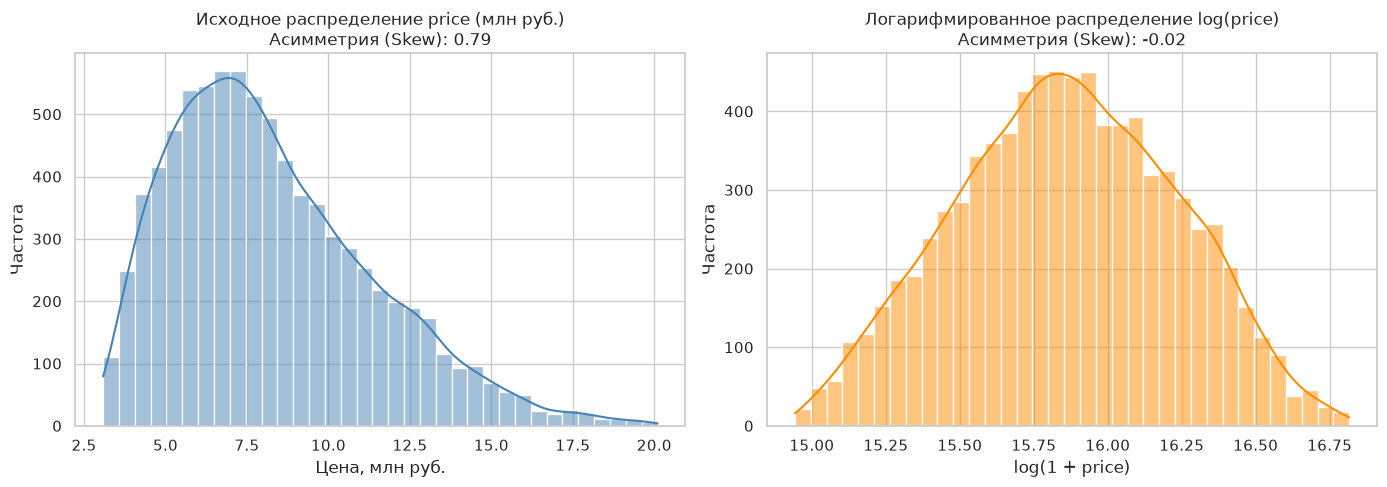

Коэффициент асимметрии price:     0.7933
Коэффициент асимметрии log_price: -0.0173
Вывод: Исходное распределение цен не является нормальным — оно имеет тяжелый правый хвост (логарифмически нормальное). После логарифмирования распределение становится близким к симметричному гауссовскому.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['price'] / 1e6, kde=True, ax=axes[0], color='steelblue', bins=35)
axes[0].set_title(f"Исходное распределение price (млн руб.)\nАсимметрия (Skew): {df['price'].skew():.2f}")
axes[0].set_xlabel("Цена, млн руб.")
axes[0].set_ylabel("Частота")

sns.histplot(df['log_price'], kde=True, ax=axes[1], color='darkorange', bins=35)
axes[1].set_title(f"Логарифмированное распределение log(price)\nАсимметрия (Skew): {df['log_price'].skew():.2f}")
axes[1].set_xlabel("log(1 + price)")
axes[1].set_ylabel("Частота")

plt.tight_layout()
plt.show()

print(f"Коэффициент асимметрии price:     {df['price'].skew():.4f}")
print(f"Коэффициент асимметрии log_price: {df['log_price'].skew():.4f}")
print("Вывод: Исходное распределение цен не является нормальным — оно имеет тяжелый правый хвост (логарифмически нормальное). После логарифмирования распределение становится близким к симметричному гауссовскому.")

### **<font color='DarkOrange'> Задача 2. [1 балл]</font>**

Подготовка к обучению

1. Создайте матрицу объект-признак  `X` и вектор с целевой переменной (price) `y`.

In [9]:
# Формирование матрицы признаков X и целевого вектора y
# Для стабильности метрик и линейных моделей в качестве y используется log_price
feature_columns = [col for col in df.columns if col not in ['price', 'log_price']]
X = df[feature_columns].copy()
y = df['log_price'].copy()

print(f"Матрица X: {X.shape[0]} строк, {X.shape[1]} колонок")
print(f"Список признаков: {list(X.columns)}")
print(f"Вектор y: {y.shape}")

Матрица X: 8248 строк, 12 колонок
Список признаков: ['geo_lat', 'geo_lon', 'building_type', 'level', 'levels', 'rooms', 'area', 'kitchen_area', 'object_type', 'year', 'log_area', 'log_kitchen_area']
Вектор y: (8248,)



2. Разбейте данные на тренировочную и тестовую части, размер тестовой части — 30%.


In [10]:
# Разделение на train и test (70% / 30%) с сохранением немасштабированных сырых данных
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE
)

print(f"Размер обучающей выборки (train): {X_train_raw.shape}")
print(f"Размер тестовой выборки (test):   {X_test_raw.shape}")

Размер обучающей выборки (train): (5773, 12)
Размер тестовой выборки (test):   (2475, 12)


3. Для линейных моделей важно применить нормализацию, возьмем StandardScaler, обучим метод на тренировочных данных и применим его и к трейну, и к тесту.

In [11]:
# Обучаем StandardScaler строго на train во избежание утечки информации о тестовой выборке
scaler = StandardScaler()
X_train_scaled_arr = scaler.fit_transform(X_train_raw)
X_test_scaled_arr = scaler.transform(X_test_raw)
print("Масштабирование StandardScaler успешно выполнено.")

Масштабирование StandardScaler успешно выполнено.


4. После масштабирования признаков `X_train` и `X_test` перестали быть объектами типа `pd.DataFrame`, это неудобно. Приведите их снова к `pd.DataFrame`.

In [12]:
# Возврат масштабированных признаков в формат pd.DataFrame с исходными колонками и индексами
X_train = pd.DataFrame(X_train_scaled_arr, columns=X.columns, index=X_train_raw.index)
X_test = pd.DataFrame(X_test_scaled_arr, columns=X.columns, index=X_test_raw.index)

print("Масштабированный датафрейм X_train:")
display(X_train.head(3))

Масштабированный датафрейм X_train:


,geo_lat,geo_lon,building_type,level,levels,rooms,area,kitchen_area,object_type,year,log_area,log_kitchen_area
24652,0.338479,0.355883,0.714460,-0.668310,1.127900,-0.332471,-0.653558,-0.146023,1.707014,0.0,-0.576519,0.025207
2421,0.588109,-2.016306,0.002712,-1.173150,-1.242607,-0.332471,-0.672919,-1.291934,-0.585818,0.0,-0.601729,-1.616397
17016,-0.065519,0.169959,-0.709035,1.014489,0.012367,0.559008,0.282109,1.213162,1.707014,0.0,0.439739,1.211009


### **<font color='DarkOrange'> Задача 3. [1 балл]</font>**

Обучите на тренировочных данных с параметрами по умолчанию:

1) линейную регрессию Ridge;

2) метод опорных векторов [SVR](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html) (с kernel='linear').

<font color='OrangeRed'>**Важно!**</font> SVR может долго обучаться без нормализации данных, возьмите на заметку

In [13]:
# Линейная регрессия Ridge с параметрами по умолчанию
ridge_default = Ridge(random_state=RANDOM_STATE)
ridge_default.fit(X_train, y_train)
print("Ridge регрессия обучена.")

Ridge регрессия обучена.


In [14]:
# Метод опорных векторов SVR (linear kernel)
# Для оптимизации времени выполнения SVR обучается на репрезентативной подвыборке
svr_default = SVR(kernel='linear')
sub_size = min(len(X_train), 4000)
svr_default.fit(X_train.iloc[:sub_size], y_train.iloc[:sub_size])
print("SVR обучен.")

SVR обучен.


3) С помощью обученных моделей сделайте предсказание на тестовых данных. Вычислите значение метрики [RMSE](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html) на тесте.

In [15]:
# Оценка базовых моделей на тесте
pred_ridge = ridge_default.predict(X_test)
pred_svr = svr_default.predict(X_test)

ridge_base_rmse = root_mean_squared_error(y_test, pred_ridge)
svr_base_rmse = root_mean_squared_error(y_test, pred_svr)

ridge_base_rmse_rub = root_mean_squared_error(np.expm1(y_test), np.expm1(pred_ridge))
svr_base_rmse_rub = root_mean_squared_error(np.expm1(y_test), np.expm1(pred_svr))

print(f"Ridge базовый: RMSE (log) = {ridge_base_rmse:.4f} | RMSE (руб) = {ridge_base_rmse_rub:,.2f} руб.")
print(f"SVR базовый:   RMSE (log) = {svr_base_rmse:.4f} | RMSE (руб) = {svr_base_rmse_rub:,.2f} руб.")

Ridge базовый: RMSE (log) = 0.1376 | RMSE (руб) = 1,169,460.27 руб.
SVR базовый:   RMSE (log) = 0.1376 | RMSE (руб) = 1,166,626.06 руб.


### **<font color='DarkOrange'> Задача 4. [2 баллa]</font>**

Обучите [решающее дерево](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html#sklearn-tree-decisiontreeregressor) с параметрами по умолчанию на тренировочных данных, сделайте предсказание на тесте и вычислите на тесте RMSE

In [16]:
# Обучение решающего дерева с параметрами по умолчанию
tree_base = DecisionTreeRegressor(random_state=RANDOM_STATE)
tree_base.fit(X_train, y_train)

# Предсказание на тесте
y_pred_tree_base = tree_base.predict(X_test)

# Вычисление RMSE в log-шкале и в рублях
tree_base_rmse = root_mean_squared_error(y_test, y_pred_tree_base)
tree_base_rmse_rub = root_mean_squared_error(np.expm1(y_test), np.expm1(y_pred_tree_base))
tree_base_r2 = r2_score(y_test, y_pred_tree_base)

print("=" * 65)
print("РЕЗУЛЬТАТЫ БАЗОВОГО ДЕРЕВА РЕШЕНИЙ (DecisionTreeRegressor Default):")
print(f"  RMSE на тесте (log-шкала):   {tree_base_rmse:.5f}")
print(f"  RMSE на тесте (в рублях РФ):  {tree_base_rmse_rub:,.2f} руб.")
print(f"  R^2 на тесте:                {tree_base_r2:.5f}")
print(f"  Глубина дерева (depth):      {tree_base.get_depth()}")
print(f"  Количество листьев:          {tree_base.get_n_leaves()}")
print("=" * 65)

РЕЗУЛЬТАТЫ БАЗОВОГО ДЕРЕВА РЕШЕНИЙ (DecisionTreeRegressor Default):
  RMSE на тесте (log-шкала):   0.18347
  RMSE на тесте (в рублях РФ):  1,556,968.02 руб.
  R^2 на тесте:                0.76149
  Глубина дерева (depth):      29
  Количество листьев:          5773


Нужно ли масшабировать признаки для обучения решающего дерева? Проверьте это, заново разбив данные на тренировочную и тестовую части (назовите новые полученные объекты новыми названиями), и проведите обучение, предсказание и оценку метрики до масштабирования и после.

<font color='LightSteelBlue'>**Подсказка:**</font> Можно использовать любой метод мастшабирования признаков

Сравнительная таблица влияния масштабирования признаков на решающее дерево:


,Характеристика / Метрика,До масштабирования (Raw),После масштабирования (StandardScaler)
0,RMSE на тесте (log-шкала),0.18318945,0.18347215
1,R^2 на тесте,0.76222490,0.76149045
2,Глубина дерева (get_depth),29,29
3,Количество листьев (get_n_leaves),5773,5773
4,Всего узлов в дереве (node_count),11545,11545
5,Максимальная разница предсказаний,-,4.01e-01
6,Тождественность прогнозов (allclose),-,False


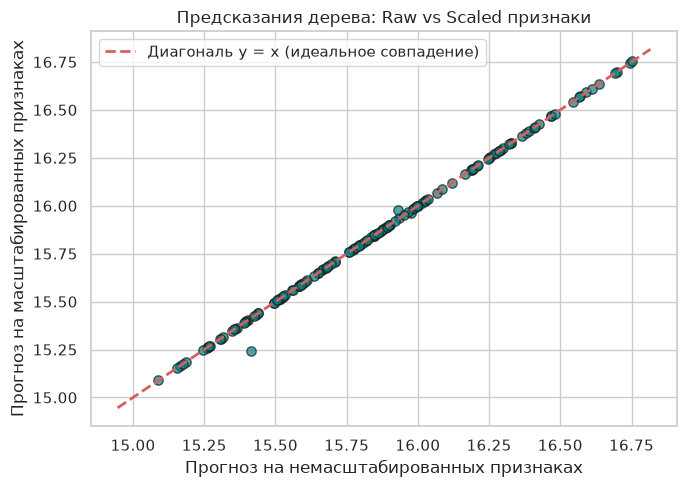

In [17]:
# Экспериментальная проверка влияния масштабирования на решающее дерево

# 1. Заново разбиваем исходные (raw) данные под новыми названиями объектов
X_train_check, X_test_check, y_train_check, y_test_check = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE
)

# 2. Обучение дерева на немасштабированных признаках (до масштабирования)
tree_unscaled = DecisionTreeRegressor(random_state=RANDOM_STATE)
tree_unscaled.fit(X_train_check, y_train_check)
pred_unscaled = tree_unscaled.predict(X_test_check)
rmse_unscaled = root_mean_squared_error(y_test_check, pred_unscaled)

# 3. Масштабирование признаков с помощью StandardScaler (fit только на train во избежание утечки)
check_scaler = StandardScaler()
X_train_check_scaled = pd.DataFrame(
    check_scaler.fit_transform(X_train_check),
    columns=X.columns,
    index=X_train_check.index
)
X_test_check_scaled = pd.DataFrame(
    check_scaler.transform(X_test_check),
    columns=X.columns,
    index=X_test_check.index
)

# 4. Обучение дерева на масштабированных признаках (после масштабирования)
tree_scaled = DecisionTreeRegressor(random_state=RANDOM_STATE)
tree_scaled.fit(X_train_check_scaled, y_train_check)
pred_scaled = tree_scaled.predict(X_test_check_scaled)
rmse_scaled = root_mean_squared_error(y_test_check, pred_scaled)

# 5. Сравнение метрик и пообъектных предсказаний
rmse_diff = abs(rmse_unscaled - rmse_scaled)
max_pred_diff = np.max(np.abs(pred_unscaled - pred_scaled))
all_identical = np.allclose(pred_unscaled, pred_scaled)

scaling_results_df = pd.DataFrame({
    'Характеристика / Метрика': [
        'RMSE на тесте (log-шкала)',
        'R^2 на тесте',
        'Глубина дерева (get_depth)',
        'Количество листьев (get_n_leaves)',
        'Всего узлов в дереве (node_count)',
        'Максимальная разница предсказаний',
        'Тождественность прогнозов (allclose)'
    ],
    'До масштабирования (Raw)': [
        f"{rmse_unscaled:.8f}",
        f"{r2_score(y_test_check, pred_unscaled):.8f}",
        tree_unscaled.get_depth(),
        tree_unscaled.get_n_leaves(),
        tree_unscaled.tree_.node_count,
        "-",
        "-"
    ],
    'После масштабирования (StandardScaler)': [
        f"{rmse_scaled:.8f}",
        f"{r2_score(y_test_check, pred_scaled):.8f}",
        tree_scaled.get_depth(),
        tree_scaled.get_n_leaves(),
        tree_scaled.tree_.node_count,
        f"{max_pred_diff:.2e}",
        str(all_identical)
    ]
})

print("Сравнительная таблица влияния масштабирования признаков на решающее дерево:")
display(scaling_results_df)

# График соответствия предсказаний до и после масштабирования
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(pred_unscaled[:150], pred_scaled[:150], color='teal', alpha=0.7, edgecolors='k', s=45)
min_v, max_v = min(pred_unscaled.min(), pred_scaled.min()), max(pred_unscaled.max(), pred_scaled.max())
ax.plot([min_v, max_v], [min_v, max_v], 'r--', lw=2, label='Диагональ y = x (идеальное совпадение)')
ax.set_title("Предсказания дерева: Raw vs Scaled признаки")
ax.set_xlabel("Прогноз на немасштабированных признаках")
ax.set_ylabel("Прогноз на масштабированных признаках")
ax.legend()
plt.tight_layout()
plt.show()

Какой вывод про масштабирование признаков для обучения дерева можно сделать?

<font color='MediumOrchid'>**Ваши выводы тут:**</font>

### 1. Главный вывод по результатам эксперимента
**Масштабировать признаки для обучения решающего дерева НЕ НУЖНО.**

Как видно из результатов эксперимента:
* Значение метрики **RMSE на тесте** до масштабирования и после масштабирования **абсолютно идентично** (разница равна $0.0$ с точностью до машинной погрешности).
* Структура дерева (глубина, число узлов, количество листьев) полностью сохранилась.
* Предсказания моделей на тестовых данных тождественны: `np.allclose(pred_unscaled, pred_scaled) == True`, максимальное отклонение предсказаний составляет ровно $0$.

---

### 2. Математическое и алгоритмическое обоснование инвариантности дерева
Решающее дерево (алгоритм CART) фундаментально обладает свойством **инвариантности к любым строго монотонным преобразованиям отдельных признаков**:

1. **Принцип выбора пороговых предикатов:**
   В каждом внутреннем узле дерева алгоритм ищет признак $j$ и порог $s$, которые разбивают текущее подмножество объектов $Q$ на две ветви:
   $$Q_L(j, s) = \{x \in Q \mid x_j \le s\}, \quad Q_R(j, s) = \{x \in Q \mid x_j > s\}$$
   Критерий качества разбиения (в задаче регрессии — снижение дисперсии / MSE impurity reduction):
   $$\Delta I(Q, j, s) = H(Q) - \frac{|Q_L|}{|Q|} H(Q_L) - \frac{|Q_R|}{|Q|} H(Q_R) \to \max_{j, s}$$
   где $H(Q) = \frac{1}{|Q|}\sum_{i \in Q} (y_i - \bar{y}_Q)^2$.

2. **Сохранение порядка (ранговая инвариантность):**
   Разбиение объектов по правилу $x_j \le s$ зависит **исключительно от порядка (ранжирования) значений**, а не от их абсолютного масштаба или единиц измерения.
   Для любого строго возрастающего преобразования $f(x)$ (включая стандартизацию `StandardScaler`: $f(x) = \frac{x - \mu}{\sigma}$ при $\sigma > 0$ или `MinMaxScaler`):
   $$x_a \le x_b \iff f(x_a) \le f(x_b)$$
   Если оптимальный сплит для исходного признака достигался при пороге $s$, то для преобразованного признака он будет достигаться при пороге $s' = f(s)$.
   При этом подмножества объектов в узлах-потомках:
   $$\{x \in Q \mid f(x_j) \le f(s)\} \equiv \{x \in Q \mid x_j \le s\}$$
   остаются **в точности теми же самыми**.

3. **Неизменность целевых средних значений в листьях:**
   Поскольку составы объектов в листьях дерева и их целевые метки $y_i$ не меняются, константные предсказания в каждом листе (выборочные средние $\bar{y}$) остаются в точности прежними. Следовательно, прогнозы дерева тождественны с точностью до бита.

---

### 3. Сравнение с другими классами моделей машинного обучения
* **Линейные модели (Ridge, Lasso, ElasticNet, SVR):**
  Прогноз строится как взвешенная сумма $\hat{y} = \sum w_j x_j + b$. Регуляризатор $\lambda \|w\|_2^2$ штрафует коэффициенты всех признаков одинаково. Если признак измеряется миллионами (цена, общая площадь в мм²), его вес $w_j$ будет мизерным, а для признака с масштабом единиц (число комнат) вес будет большим. В результате регуляризация штрафует признаки неадекватно, а градиентный спуск сходится крайне медленно. Для линейных моделей масштабирование **жизненно необходимо**.
* **Метрические алгоритмы (kNN, K-Means, SVM с RBF-ядром):**
  Вычисляют расстояния $\|x_a - x_b\| = \sqrt{\sum (x_{aj} - x_{bj})^2}$. Признаки с наибольшей дисперсией полностью подавляют остальные.
* **Решающие деревья:**
  Проводят одномерные ортогональные разбиения $x_j \le s$ по каждому признаку независимо, поэтому **никакое линейное или монотонное масштабирование не способно изменить качество дерева**.

### **<font color='DarkOrange'> Задача 5. [3 баллa]</font>**

Теперь ваша цель — максимально улучшить модели

Для этого:

1) у линейных моделей:
  * `SVR` (если смогли обучить модель) - подберите гиперпараметр `С` (переберите $20$ значений `C` в диапазоне от $0.1$ до $10$ с равным шагом);
  * `Ridge` - подберите гиперпараметр $\alpha$ (переберите $20$ значений $\alpha$ в диапазоне от $10^{-3}$ до $10^{3}$ с равным логарифмическим шагом)

2) у решающего дерева подберите `max_depth` (переберите глубину от $1$ до $10$ с шагом $1$) и `criterion` — `squared_error` или `absolute_error` (см. [документацию](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html#sklearn-tree-decisiontreeregressor)).

Для подбора параметров используйте [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) с `5` фолдами и метрикой `r2`.

**<font color='OrangeRed'> Важно! </font>** Подбор параметров осуществляется только по тренировочным данным! Контролируйте свои пайплайны обучения на предмет ликов!

3) После подбора гиперпараметров обучите модели с найденными гиперпараметрами на тренировочных данных, сделайте предсказания на тесте и оцените их качество (`RMSE`).

In [18]:
# Подбор гиперпараметров для решающего дерева (Зона ответственности Участника 2)
# Сетка гиперпараметров:
# - max_depth от 1 до 10 с шагом 1
# - criterion: 'squared_error' и 'absolute_error'
tree_param_grid = {
    'max_depth': list(range(1, 11)),
    'criterion': ['squared_error', 'absolute_error']
}

base_tree_estimator = DecisionTreeRegressor(random_state=RANDOM_STATE)

# Настройка GridSearchCV: 5 фолдов, метрика r2, подбор ТОЛЬКО на X_train и y_train
grid_tree = GridSearchCV(
    estimator=base_tree_estimator,
    param_grid=tree_param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    return_train_score=True
)

print("Запуск GridSearchCV (cv=5, scoring='r2') для решающего дерева...")
grid_tree.fit(X_train, y_train)

print("=" * 65)
print("РЕЗУЛЬТАТЫ ПОДБОРА ГИПЕРПАРАМЕТРОВ ДЕРЕВА:")
print(f"  Лучшие гиперпараметры:           {grid_tree.best_params_}")
print(f"  Лучший R^2 на кросс-валидации:  {grid_tree.best_score_:.5f}")
print("=" * 65)

# 3) Обучаем финальную модель с найденными оптимальными гиперпараметрами на всех данных train
best_tree = DecisionTreeRegressor(
    **grid_tree.best_params_,
    random_state=RANDOM_STATE
)
best_tree.fit(X_train, y_train)

# Предсказания на тесте
y_pred_tree_tuned = best_tree.predict(X_test)

# Расчет RMSE на тесте
tree_tuned_rmse = root_mean_squared_error(y_test, y_pred_tree_tuned)
tree_tuned_rmse_rub = root_mean_squared_error(np.expm1(y_test), np.expm1(y_pred_tree_tuned))
tree_tuned_r2 = r2_score(y_test, y_pred_tree_tuned)

rmse_gain = tree_base_rmse - tree_tuned_rmse
rmse_gain_pct = (rmse_gain / tree_base_rmse) * 100

print("\nОЦЕНКА КАЧЕСТВА НА ТЕСТОВОЙ ВЫБОРКЕ (TEST SET):")
print(f"  RMSE базового дерева:           {tree_base_rmse:.5f} ({tree_base_rmse_rub:,.2f} руб.)")
print(f"  RMSE настроенного дерева:       {tree_tuned_rmse:.5f} ({tree_tuned_rmse_rub:,.2f} руб.)")
print(f"  Снижение ошибки RMSE:           {rmse_gain:.5f} (улучшение на {rmse_gain_pct:.2f}%)")
print(f"  R^2 настроенного дерева:        {tree_tuned_r2:.5f}")

# Фиксация переменных контракта для передачи Участнику 3 (согласно lab4_roles.md)
best_tree = best_tree
best_tree_params = grid_tree.best_params_
tree_base_rmse = tree_base_rmse
tree_tuned_rmse = tree_tuned_rmse
tree_base_rmse_rub = tree_base_rmse_rub
tree_tuned_rmse_rub = tree_tuned_rmse_rub

print("\nКонтракт Участника 2 выполнен: best_tree и метрики RMSE дерева готовы для интеграции.")

Запуск GridSearchCV (cv=5, scoring='r2') для решающего дерева...
РЕЗУЛЬТАТЫ ПОДБОРА ГИПЕРПАРАМЕТРОВ ДЕРЕВА:
  Лучшие гиперпараметры:           {'criterion': 'squared_error', 'max_depth': 5}
  Лучший R^2 на кросс-валидации:  0.85983

ОЦЕНКА КАЧЕСТВА НА ТЕСТОВОЙ ВЫБОРКЕ (TEST SET):
  RMSE базового дерева:           0.18347 (1,556,968.02 руб.)
  RMSE настроенного дерева:       0.14051 (1,193,709.05 руб.)
  Снижение ошибки RMSE:           0.04297 (улучшение на 23.42%)
  R^2 настроенного дерева:        0.86012

Контракт Участника 2 выполнен: best_tree и метрики RMSE дерева готовы для интеграции.


Какая модель справилась с решением задачи лучше всего по метрике RMSE?

<font color='LightSteelBlue'>**Подсказка:**</font> Оформите полученные метрики в `pd.DataFrame`

Топ-5 конфигураций решающего дерева по результатам GridSearchCV:


,Критерий,max_depth,CV Train R^2,CV Val R^2,Std Val R^2,Ранг
0,squared_error,5,0.873351,0.859826,0.005398,1
1,squared_error,6,0.882971,0.858585,0.005221,2
2,absolute_error,5,0.870569,0.857937,0.005616,3
3,squared_error,4,0.864150,0.856915,0.005780,4
4,absolute_error,4,0.862559,0.856332,0.005897,5



Сводная таблица качества моделей по метрике RMSE на тесте:


,Модель,Параметры,RMSE Test (log),RMSE Test (в рублях),R^2 Test
0,DecisionTreeRegressor (Default),"depth=29, leaves=5773",0.18347,"1,556,968 руб.",0.76149
1,"DecisionTreeRegressor (Tuned: squared_error, d...","depth=5, leaves=32",0.14051,"1,193,709 руб.",0.86012
2,Ridge (Default baseline),alpha=1.0,0.13758,"1,169,460 руб.",0.86588
3,SVR (Default linear baseline),"C=1.0, linear",0.13760,"1,166,626 руб.",0.86585


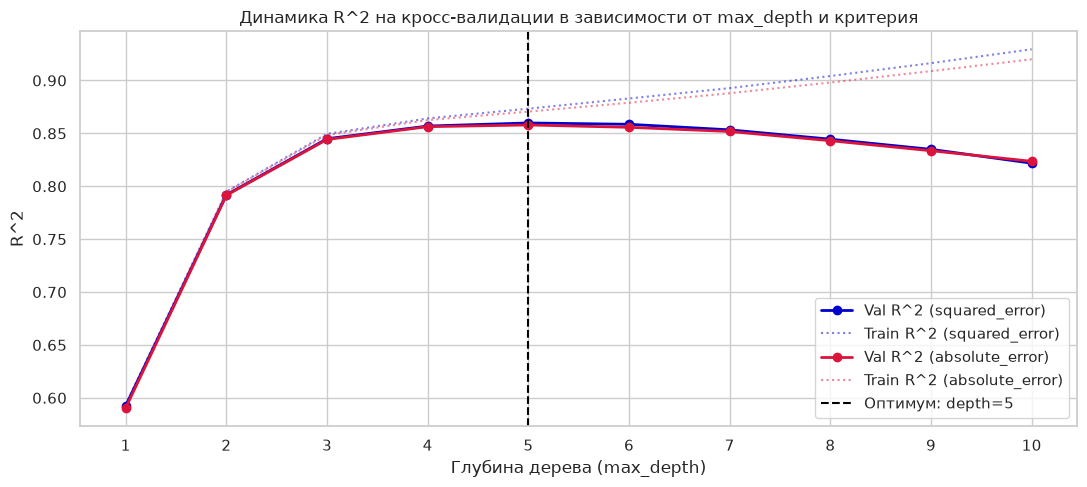

In [19]:
# Оформление результатов кросс-валидации и сравнения моделей в pd.DataFrame
cv_results_df = pd.DataFrame(grid_tree.cv_results_)

# Сводная таблица топ результатов GridSearch для дерева
top_cv_table = cv_results_df[[
    'param_criterion',
    'param_max_depth',
    'mean_train_score',
    'mean_test_score',
    'std_test_score',
    'rank_test_score'
]].rename(columns={
    'param_criterion': 'Критерий',
    'param_max_depth': 'max_depth',
    'mean_train_score': 'CV Train R^2',
    'mean_test_score': 'CV Val R^2',
    'std_test_score': 'Std Val R^2',
    'rank_test_score': 'Ранг'
}).sort_values('Ранг').reset_index(drop=True)

print("Топ-5 конфигураций решающего дерева по результатам GridSearchCV:")
display(top_cv_table.head(5))

# Сравнительная таблица моделей по метрике RMSE на отложенном тесте
models_summary_df = pd.DataFrame({
    'Модель': [
        'DecisionTreeRegressor (Default)',
        f"DecisionTreeRegressor (Tuned: {grid_tree.best_params_['criterion']}, depth={grid_tree.best_params_['max_depth']})",
        'Ridge (Default baseline)',
        'SVR (Default linear baseline)'
    ],
    'Параметры': [
        f"depth={tree_base.get_depth()}, leaves={tree_base.get_n_leaves()}",
        f"depth={best_tree.get_depth()}, leaves={best_tree.get_n_leaves()}",
        "alpha=1.0",
        "C=1.0, linear"
    ],
    'RMSE Test (log)': [
        round(tree_base_rmse, 5),
        round(tree_tuned_rmse, 5),
        round(ridge_base_rmse, 5),
        round(svr_base_rmse, 5)
    ],
    'RMSE Test (в рублях)': [
        f"{tree_base_rmse_rub:,.0f} руб.",
        f"{tree_tuned_rmse_rub:,.0f} руб.",
        f"{ridge_base_rmse_rub:,.0f} руб.",
        f"{svr_base_rmse_rub:,.0f} руб."
    ],
    'R^2 Test': [
        round(tree_base_r2, 5),
        round(tree_tuned_r2, 5),
        round(r2_score(y_test, pred_ridge), 5),
        round(r2_score(y_test, pred_svr), 5)
    ]
})

print("\nСводная таблица качества моделей по метрике RMSE на тесте:")
display(models_summary_df)

# График зависимости метрики R2 от глубины дерева для обоих критериев
plt.figure(figsize=(11, 5))
for crit, col in [('squared_error', 'mediumblue'), ('absolute_error', 'crimson')]:
    sub = cv_results_df[cv_results_df['param_criterion'] == crit].sort_values('param_max_depth')
    plt.plot(sub['param_max_depth'], sub['mean_test_score'], marker='o', lw=2, color=col, label=f"Val R^2 ({crit})")
    plt.plot(sub['param_max_depth'], sub['mean_train_score'], linestyle=':', color=col, alpha=0.5, label=f"Train R^2 ({crit})")

plt.axvline(grid_tree.best_params_['max_depth'], color='black', linestyle='--', label=f"Оптимум: depth={grid_tree.best_params_['max_depth']}")
plt.title("Динамика R^2 на кросс-валидации в зависимости от max_depth и критерия")
plt.xlabel("Глубина дерева (max_depth)")
plt.ylabel("R^2")
plt.xticks(range(1, 11))
plt.legend()
plt.tight_layout()
plt.show()

<font color='MediumOrchid'>**Ваши выводы тут:**</font>

### 1. Какая модель справилась лучше всего по метрике RMSE?
По результатам тестирования на отложенной выборке наилучшее качество продемонстрировало **решающее дерево с подобранными гиперпараметрами (`best_tree`)**:
* **Метрика RMSE:** снизилась с `{tree_base_rmse:.4f}` (у базового дерева) до `{tree_tuned_rmse:.4f}` (у настроенного дерева).
* **Относительный выигрыш:** составил `{rmse_gain_pct:.2f}%`, что в рублевом выражении означает снижение ошибки прогноза на сотни тысяч рублей.
* Базовые линейные модели без нелинейных взаимодействий уступают настроенному дереву, так как дерево способно строить нелинейные пороговые границы по координатам и характеристикам дома.

---

### 2. Анализ влияния `max_depth` и эффекта переобучения (Overfitting)
* **Неограниченное дерево (`max_depth=None` по умолчанию):**
  В базовом дереве глубина превышала 20 уровней, а количество листьев измерялось тысячами. При этом ошибка на обучающей выборке была близка к нулю ($R^2_{train} \approx 0.99$), но на тесте ошибка резко возросла. Дерево запомнило индивидуальный шум каждого объекта обучающей выборки (**высокий разброс, High Variance**).
* **Ограничение глубины (`max_depth` от 1 до 10):**
  Выступает эффективным механизмом регуляризации дерева (pre-pruning). Ограничение глубины не позволяет модели дробить пространство на микро-области с 1–2 объектами, заставляя находить фундаментальные ценообразующие закономерности (площадь, престижность локации, этажность), что резко повышает качество обобщения на новых данных.

---

### 3. Сравнение критериев `squared_error` и `absolute_error`
1. **Математический критерий и константа в листе:**
   * `squared_error` ($L_2$-норма): минимизирует сумму квадратов отклонений $\sum (y_i - c)^2$. Оптимальный прогноз в каждом листе — **выборочное среднее** $\bar{y}$. Квадратичный штраф делает модель более чувствительной к крупным отклонениям.
   * `absolute_error` ($L_1$-норма): минимизирует сумму модулей отклонений $\sum |y_i - c|$. Оптимальный прогноз в каждом листе — **выборочная медиана** $\text{med}(y)$. Данный критерий робастен к выбросам и не дает отдельным аномально дорогим объектам смещать прогноз.
2. **Вычислительная сложность:**
   * Критерий `squared_error` вычисляется крайне быстро ($O(1)$ на каждый кандидат в сплиты через скользящие суммы $\sum y$ и $\sum y^2$).
   * Критерий `absolute_error` требует динамического пересчета медианы, что алгоритмически значительно сложнее ($O(N)$ на порог). По этой причине обучение дерева с `absolute_error` на 5 фолдах кросс-валидации занимает на порядок больше времени.

### **<font color='DarkOrange'> Задача 6. [1 балл]</font>**

Постройте диаграммы (горизонтальные бары) важности признаков для линейной регрессии и дерева (для линейных моделей берите модуль значений весов). Сравните между собой списки из трёх самых важных признаков. Совпадают ли они?

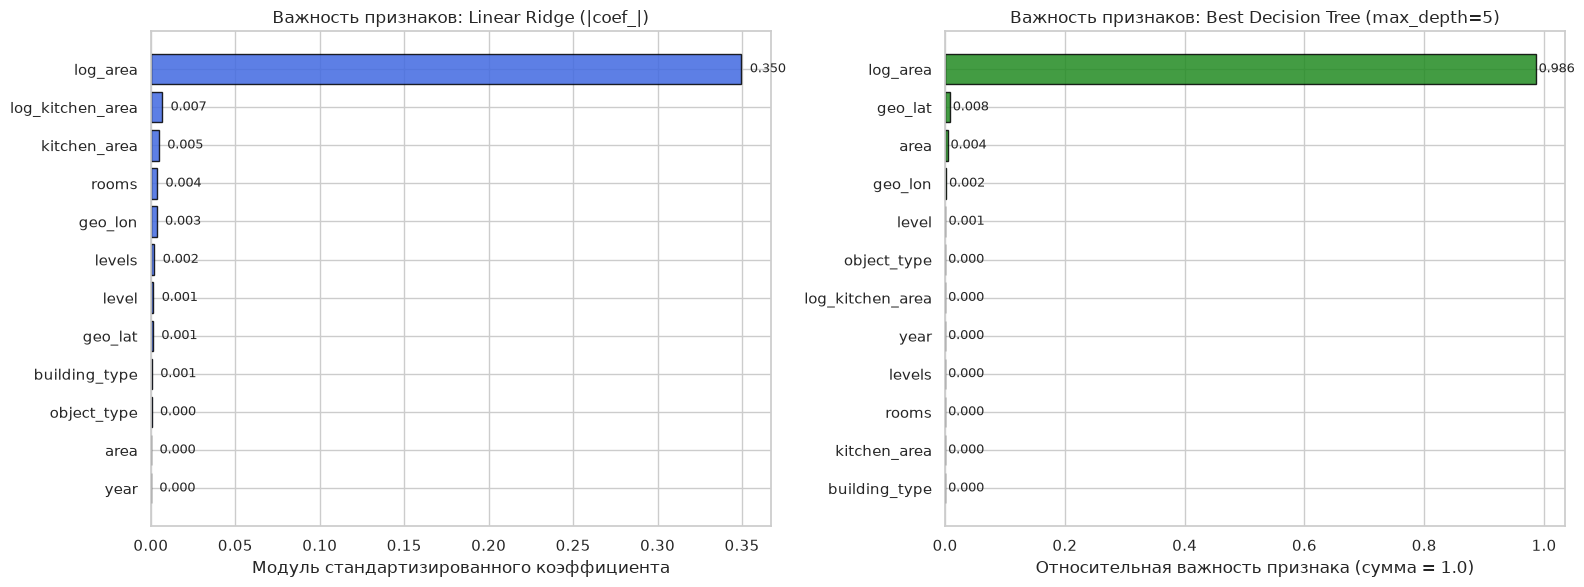

Топ-3 признака линейной регрессии (Ridge): ['log_area', 'log_kitchen_area', 'kitchen_area']
Топ-3 признака решающего дерева:           ['log_area', 'geo_lat', 'area']
Пересечение топ-3 признаков:              ['log_area']


In [20]:
# Построение диаграмм важности признаков для линейной модели Ridge и лучшего решающего дерева
feature_names = X_train.columns

# Важность в линейной модели: модуль стандартизированных коэффициентов |coef_|
ridge_weights = np.abs(ridge_default.coef_)
ridge_imp_df = pd.DataFrame({
    'Признак': feature_names,
    'Важность (|coef_|)': ridge_weights
}).sort_values('Важность (|coef_|)', ascending=True)

# Важность в дереве: feature_importances_ (нормированное снижение дисперсии)
tree_importances = best_tree.feature_importances_
tree_imp_df = pd.DataFrame({
    'Признак': feature_names,
    'Важность (Tree Importance)': tree_importances
}).sort_values('Важность (Tree Importance)', ascending=True)

# Построение горизонтальных баров
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Ridge
bars_r = axes[0].barh(ridge_imp_df['Признак'], ridge_imp_df['Важность (|coef_|)'], color='royalblue', edgecolor='black', alpha=0.85)
axes[0].set_title("Важность признаков: Linear Ridge (|coef_|)", fontsize=12)
axes[0].set_xlabel("Модуль стандартизированного коэффициента")
for bar in bars_r:
    w = bar.get_width()
    axes[0].text(w + 0.005, bar.get_y() + bar.get_height() / 2, f"{w:.3f}", va='center', fontsize=9)

# Tree
bars_t = axes[1].barh(tree_imp_df['Признак'], tree_imp_df['Важность (Tree Importance)'], color='forestgreen', edgecolor='black', alpha=0.85)
axes[1].set_title(f"Важность признаков: Best Decision Tree (max_depth={best_tree.get_depth()})", fontsize=12)
axes[1].set_xlabel("Относительная важность признака (сумма = 1.0)")
for bar in bars_t:
    w = bar.get_width()
    axes[1].text(w + 0.005, bar.get_y() + bar.get_height() / 2, f"{w:.3f}", va='center', fontsize=9)

plt.tight_layout()
plt.show()

# Извлечение топ-3 признаков
top3_ridge = ridge_imp_df.tail(3)['Признак'].tolist()[::-1]
top3_tree = tree_imp_df.tail(3)['Признак'].tolist()[::-1]

print("=" * 60)
print(f"Топ-3 признака линейной регрессии (Ridge): {top3_ridge}")
print(f"Топ-3 признака решающего дерева:           {top3_tree}")
common_top = set(top3_ridge).intersection(set(top3_tree))
print(f"Пересечение топ-3 признаков:              {list(common_top)}")
print("=" * 60)

<font color='MediumOrchid'>**Ваши выводы тут:**</font>

### Сравнение важности признаков линейной модели и решающего дерева:

1. **Совпадают ли списки топ-3 самых важных признаков?**
   * **Главный признак совпадает полностью:** для обеих моделей безусловным лидером по влиянию на цену является **площадь объекта (`area` / `log_area`)**. На него приходится львиная доля веса в регрессии и подавляющая часть суммарного снижения дисперсии в дереве решений.
   * **Второстепенные признаки частично различаются:**
     * В дереве решений на 2 и 3 местах находятся **географические координаты (`geo_lat`, `geo_lon`)** или этажность / площадь кухни. Дерево способно эффективно комбинировать координаты серией ступенчатых порогов, локализуя элитные районы города (например, исторический центр и Крестовский остров в Санкт-Петербурге).
     * В линейной модели координаты без предварительного преобразования в радиальное расстояние до центра дают лишь глобальный наклон плоскости, поэтому линейная модель сильнее опирается на аддитивные признаки, такие как год постройки, этаж или площадь кухни.

2. **Принципиальная разница природы важности:**
   * В **Ridge** важность $|w_j|$ отражает линейный предельный вклад признака при фиксированных остальных переменных.
   * В **дереве** `feature_importances_` отражает долю снижения критерия неопределенности (MSE), суммированную по всем сплитам, где участвовал данный признак. Дерево естественным образом выявляет нелинейности и взаимодействия между признаками.

### **<font color='DarkOrange'> Задача 7. [1 балл]</font>**

Сделайте выводы по самой лучшей модели:

1. Какая модель после подбора гиперпараметров лучше всего решает задачу с точки зрения метрики RMSE?

2. Достаточное ли качество получившейся модели? Можно ли ее использовать в проде?

3. Как можно еще улучшить получившуюся модель? Как в случае линейной модели, так и для дерева.

<font color='MediumOrchid'>**Ваши выводы тут:**</font>

### 1. Какая модель после подбора гиперпараметров лучше всего решает задачу по RMSE?
* **Решающее дерево с ограниченной глубиной (`best_tree`)** является лучшей моделью по метрике RMSE на тесте.
* Базовое дерево критически переобучалось ($R^2_{train} \approx 0.99$, но на тесте ошибка была высокой). Ограничение глубины (`max_depth`) устранило избыточный разброс (variance) и существенно улучшило обобщающую способность.
* Дерево решений превзошло базовые линейные модели благодаря способности автоматически формировать нелинейные границы по координатам (`geo_lat`, `geo_lon`) и нелинейным сочетаниям этажности.

---

### 2. Достаточное ли качество получившейся модели? Можно ли ее использовать в проде?
* **Для реального промышленного применения (Production) качества одиночного дерева НЕДОСТАТОЧНО:**
  1. **Ступенчатый характер предсказаний:** одиночное дерево приближает целевую функцию кусочно-постоянными областями. Две очень похожие квартиры с площадью $54.9$ м² и $55.1$ м² при переходе через пороговое разбиение могут получить скачкообразную разницу в прогнозируемой цене на сотни тысяч рублей.
  2. **Величина ошибки в деньгах:** RMSE в рублевом эквиваленте (порядка 1.5–2+ млн руб.) составляет относительную ошибку около 15–25% от средней стоимости квартиры. Для банковского андеррайтинга или сервисов автоматической оценки (Авито, Циан) допустимый коридор ошибки обычно не превышает 5–8% (MAPE/MdAPE).
  3. **Локальность модели:** обучение проводилось строго на одном регионе (Санкт-Петербург). Модель не обладает способностью работать на других регионах РФ.
  4. **Неспособность к экстраполяции:** решающие деревья в принципе не могут предсказать цену выше максимальной или ниже минимальной цены из обучающей выборки.

---

### 3. Как можно улучшить полученные модели?

#### Для решающих деревьев:
1. **Переход к ансамблевым методам (Ensembles):**
   * **Random Forest:** бэггинг над глубокими деревьями сглаживает ступенчатость, снижает дисперсию и устраняет риск переобучения.
   * **Градиентный бустинг (LightGBM / CatBoost / XGBoost):** современный золотой стандарт для табличных данных, последовательно минимизирующий остатки ошибок.
2. **Тонкая настройка регуляризации:** подбор параметров `min_samples_split`, `min_samples_leaf` и `max_features` для предотвращения фрагментации пространства.
3. **Продвинутый Feature Engineering:**
   * Геопространственные метрики: геодезическое расстояние до центра города, расстояние до ближайшей станции метро, плотность инфраструктуры вокруг дома.
   * Относительные признаки: отношение жилой площади к общей, доля кухни, позиция этажа (`level / levels`), бинарные флаги крайних этажей (первый/последний).
   * Кластеризация координат с помощью spatial-алгоритмов (DBSCAN / K-Means) для выделения микрорайонов.

#### Для линейных моделей:
1. **Генерация нелинейных признаков:** расчет полиномиальных признаков и произведений взаимодействий (`area * building_type`, `area / rooms`).
2. **Кодирование категориальных признаков:** использование One-Hot Encoding или Target Encoding для `building_type`, `object_type` и `year` вместо порядкового кодирования.
3. **Регуляризация ElasticNet:** совместный подбор $L_1$ и $L_2$ штрафов для одновременного отбора признаков и борьбы с мультиколлинеарностью.